## Install Necessary Python Modules

In [1]:
!pip install -q laya pandas scikit-learn matplotlib transformers>=4.48.0

## Get the Cleaned Data

In [2]:
from google.colab import drive
drive.mount('/content/drive')
FILE_PATH = '/content/drive/MyDrive/cleaned_manual.csv'   # <-- edit

Mounted at /content/drive


## All Import Statements

In [3]:
import os
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import laya
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import json
from transformers import AutoTokenizer
from huggingface_hub import snapshot_download
from laya.agent import _fix_tokenizer_config
from laya.train import items_from_rows
import gc, math, random, time
from safetensors.torch import load_file
from laya.common import build_model, collate_items
from laya.calibrate import fit_temperature_map
from laya.train import (calibration_records, encode_item, rlcd_loss,
                        save_checkpoint, sigma_at, split_calibration)

## Split Train and Validation Set

In [4]:
TEXT_COL  = "message"     # <-- column with the input text
LABEL_COL = "label"    # <-- column with the ground-truth label

df = pd.read_csv(FILE_PATH)            # add encoding="latin-1" or sep=";" if it fails to parse
# print(df)
df = df[[TEXT_COL, LABEL_COL]].dropna()
df[TEXT_COL]  = df[TEXT_COL].astype(str)
df[LABEL_COL] = df[LABEL_COL].astype(str)
print(f"Dataframe Shape: {df.shape}")

train_df, temp_df = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df[LABEL_COL]
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df[LABEL_COL]
)
print(len(train_df), "train /", len(val_df), "validation /", len(test_df), "test")

Dataframe Shape: (24369, 2)
19495 train / 2437 validation / 2437 test


## Fine Tunning Section (Run only if needed)

Tesla T4


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 39 files:   0%|          | 0/39 [00:00<?, ?it/s]

19495 training items (skipped {})
2437 validation items (skipped {})
Training on 19095 items (400 held out for calibration)


/tmp/ipykernel_521/3731710172.py:181: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


  epoch 1/1 | step 200/2387 | train loss -0.0040 | val loss 0.6995
  epoch 1/1 | step 400/2387 | train loss -0.0000 | val loss 0.8456
  epoch 1/1 | step 600/2387 | train loss -0.0000 | val loss 0.7793
  epoch 1/1 | step 800/2387 | train loss -0.2770 | val loss 0.6514
  epoch 1/1 | step 1000/2387 | train loss 0.0043 | val loss 0.9442
  epoch 1/1 | step 1200/2387 | train loss -0.0376 | val loss 0.6946
  epoch 1/1 | step 1400/2387 | train loss -0.0039 | val loss 0.6929
  epoch 1/1 | step 1600/2387 | train loss -0.0000 | val loss 0.6478
  epoch 1/1 | step 1800/2387 | train loss -0.0000 | val loss 0.7096
  epoch 1/1 | step 2000/2387 | train loss -0.0106 | val loss 0.6580
  epoch 1/1 | step 2200/2387 | train loss 2.1161 | val loss 0.6554
=== epoch 1/1 done in 798s | train loss 0.4198 | val loss 0.6590 ===


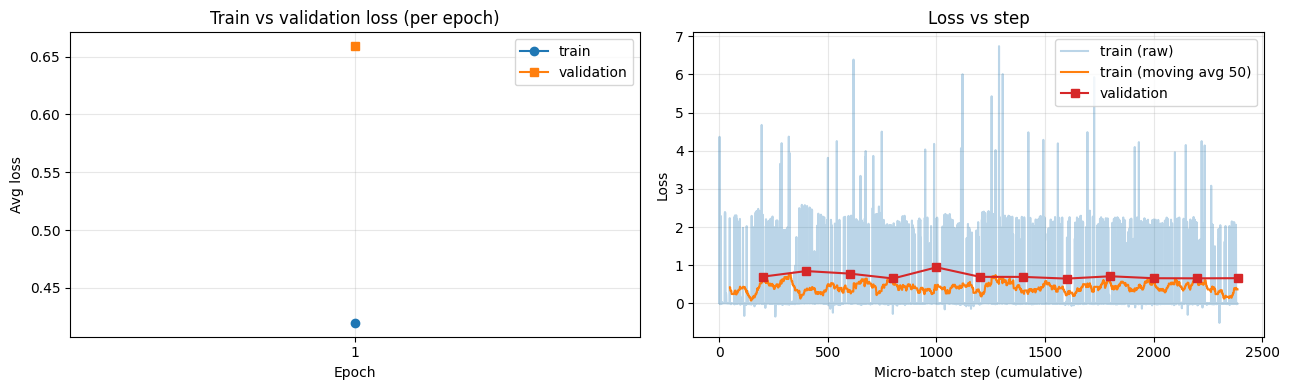

Fitted temperatures: [5.0, 1.0, 1.0]
Saved to /content/laya_offensive_ft


In [15]:
# Configurations
os.environ["USE_TF"] = "0"    # Colab has TensorFlow installed, which can make Laya hang (per the model card)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

assert torch.cuda.is_available(), "Runtime -> Change runtime type -> T4 GPU"
print(torch.cuda.get_device_name(0))

# Training
MODEL_ID = "convaiinnovations/laya"
model_dir = snapshot_download(MODEL_ID)
_fix_tokenizer_config(model_dir)
tok = AutoTokenizer.from_pretrained(os.path.join(model_dir, "tokenizer"))
with open(os.path.join(model_dir, "rl_agent_config.json")) as f:
    cfg = json.load(f)
max_len, head_max_len = cfg["max_len"], cfg["head_max_len"]

questions = {
    "label": {
        "type": "choice",
        "instructions": "Is this message offensive?",
        "criteria": {
            "0": "not offensive: neutral, polite, or harmless message",
            "1": "offensive: vulgar, insulting, hateful, abusive, threatening or harassing message aimed at a person or group",
        },
    }
}

def build_rows(frame):
    rows = []
    for text, lab in zip(frame[TEXT_COL], frame[LABEL_COL]):
        lab = str(int(float(lab)))                   # "0" or "1"
        rows.append({
            "state": {"message": text},
            "questions": questions,                  # the offensive/not offensive question from before
            "gold": {"label": {"label": lab,
                               "probabilities": {k: float(k == lab) for k in ["0", "1"]}}},
        })
    return rows

rows = []
for text, lab in zip(train_df[TEXT_COL], train_df[LABEL_COL]):
    lab = str(int(float(lab)))                       # "0" or "1"
    rows.append({
        "state": {"message": text},
        "questions": questions,                      # the offensive/not offensive question from before
        "gold": {"label": {"label": lab,
                           "probabilities": {k: float(k == lab) for k in ["0", "1"]}}},
    })


items, skipped = items_from_rows(tok, rows, max_len, head_max_len)
print(f"{len(items)} training items (skipped {skipped})")

# validation items: used ONLY to compute validation loss, never for gradient updates
val_items, val_skipped = items_from_rows(tok, build_rows(val_df), max_len, head_max_len)
print(f"{len(val_items)} validation items (skipped {val_skipped})")

agent = None                              # free the zero-shot model from GPU memory
gc.collect(); torch.cuda.empty_cache()

OUTPUT_DIR = "/content/laya_offensive_ft"
device = torch.device("cuda")

train_cfg = dict(cfg, gradient_checkpointing=True, max_tokens_per_batch=4096)
model = build_model(train_cfg, encoder_dir=os.path.join(model_dir, "encoder"))
model.load_state_dict(load_file(os.path.join(model_dir, "model.safetensors")), strict=True)
model.encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.head_checkpointing = True
model.to(device).train()

# a slice is held out for calibration and never used for training
train_items, calib_items = split_calibration(items, calib_max=400, calib_frac=0.1, seed=20260922)

EPOCHS      = 3
MICRO_BATCH = 8      # sequences per forward pass
GRAD_ACCUM  = 4      # effective batch = 32
GROUP_SIZE  = 4
LR_ENCODER, LR_HEAD = 2.5e-5, 1.0e-4
SIGMA_START, SIGMA_END = 0.4, 0.1

enc_params  = [p for n, p in model.named_parameters() if "encoder." in n]
head_params = [p for n, p in model.named_parameters() if "encoder." not in n]
optimizer = torch.optim.AdamW([{"params": enc_params, "lr": LR_ENCODER},
                               {"params": head_params, "lr": LR_HEAD}], weight_decay=0.01)
steps_per_epoch = math.ceil(len(train_items) / MICRO_BATCH)
total_updates = max(1, math.ceil(steps_per_epoch / GRAD_ACCUM) * EPOCHS)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_updates, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")

print(f"Training on {len(train_items)} items ({len(calib_items)} held out for calibration)")
EVAL_EVERY_STEPS = 200   # also compute val loss every N micro-batches (set to None for end-of-epoch only)

train_epoch_losses = []   # avg train loss per epoch
val_epoch_losses   = []   # val loss at the end of each epoch
step_losses        = []   # raw train loss for every micro-batch
val_step_points    = []   # (cumulative micro-batch step, val loss) pairs for the step plot

def compute_val_loss(sigma):
    """Average loss over the validation items (no gradient updates)."""
    model.eval()
    total, n = 0.0, 0
    for b_idx in range(0, len(val_items), MICRO_BATCH):
        chunk = val_items[b_idx:b_idx + MICRO_BATCH]
        encoded = [encode_item(tok, it, max_len, head_max_len) for it in chunk]
        batch = collate_items([encoded], tok.pad_token_id)
        with torch.autocast("cuda", dtype=torch.float16):
            logits, act = model(batch["input_ids"].to(device), batch["attention_mask"].to(device),
                                batch["marker_pos"].to(device), batch["marker_mask"].to(device),
                                batch["qtype"].to(device))
        logits = logits.float()
        loss = rlcd_loss(logits, batch["target"].to(device), batch["marker_mask"].to(device),
                         batch["qtype"].to(device), sigma, samples=GROUP_SIZE, w_sph=0.75, w_rps=1.0)
        total += loss.item(); n += 1
    model.train()
    return total / max(1, n)

def plot_losses(train_epoch_losses, val_epoch_losses, step_losses=None, val_step_points=None, smooth=50):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # Train vs validation loss per epoch
    ep = range(1, len(train_epoch_losses) + 1)
    axes[0].plot(ep, train_epoch_losses, marker="o", label="train")
    axes[0].plot(ep, val_epoch_losses, marker="s", label="validation")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Avg loss")
    axes[0].set_title("Train vs validation loss (per epoch)")
    axes[0].set_xticks(list(ep))
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Train loss per step (raw + moving average) with validation loss points on top
    if step_losses:
        axes[1].plot(step_losses, alpha=0.3, label="train (raw)")
        if len(step_losses) >= smooth:
            kernel = np.ones(smooth) / smooth
            ma = np.convolve(step_losses, kernel, mode="valid")
            axes[1].plot(range(smooth - 1, len(step_losses)), ma, label=f"train (moving avg {smooth})")
        if val_step_points:
            xs, ys = zip(*val_step_points)
            axes[1].plot(xs, ys, marker="s", color="tab:red", label="validation")
        axes[1].set_xlabel("Micro-batch step (cumulative)")
        axes[1].set_ylabel("Loss")
        axes[1].set_title("Loss vs step")
        axes[1].legend()
        axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

t0 = time.time()
for epoch in range(EPOCHS):
    random.seed(42); random.shuffle(train_items)
    sigma = sigma_at(epoch, EPOCHS, SIGMA_START, SIGMA_END)
    epoch_loss, n_batches, accum_step = 0.0, 0, 0
    model.train()
    optimizer.zero_grad(set_to_none=True)

    for b_idx in range(0, len(train_items), MICRO_BATCH):
        chunk = train_items[b_idx:b_idx + MICRO_BATCH]
        encoded = [encode_item(tok, it, max_len, head_max_len) for it in chunk]
        batch = collate_items([encoded], tok.pad_token_id)

        with torch.autocast("cuda", dtype=torch.float16):
            logits, act = model(batch["input_ids"].to(device), batch["attention_mask"].to(device),
                                batch["marker_pos"].to(device), batch["marker_mask"].to(device),
                                batch["qtype"].to(device))
        logits = logits.float()
        loss = rlcd_loss(logits, batch["target"].to(device), batch["marker_mask"].to(device),
                         batch["qtype"].to(device), sigma, samples=GROUP_SIZE, w_sph=0.75, w_rps=1.0)

        window_start = (accum_step // GRAD_ACCUM) * GRAD_ACCUM
        window_size = min(GRAD_ACCUM, steps_per_epoch - window_start)
        scaler.scale(loss / window_size).backward()
        accum_step += 1

        if accum_step % GRAD_ACCUM == 0 or (b_idx + MICRO_BATCH) >= len(train_items):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad(set_to_none=True)

        epoch_loss += loss.item(); n_batches += 1
        step_losses.append(loss.item())

        # optional mid-epoch validation (skip the last step, the end-of-epoch eval covers it)
        if EVAL_EVERY_STEPS and n_batches % EVAL_EVERY_STEPS == 0 and (b_idx + MICRO_BATCH) < len(train_items):
            v = compute_val_loss(sigma)
            val_step_points.append((len(step_losses), v))
            print(f"  epoch {epoch+1}/{EPOCHS} | step {n_batches}/{steps_per_epoch} | "
                  f"train loss {loss.item():.4f} | val loss {v:.4f}")

    # end of epoch: average train loss + full validation loss
    avg = epoch_loss / max(1, n_batches)
    val_loss = compute_val_loss(sigma)
    train_epoch_losses.append(avg)
    val_epoch_losses.append(val_loss)
    val_step_points.append((len(step_losses), val_loss))
    print(f"=== epoch {epoch+1}/{EPOCHS} done in {time.time()-t0:.0f}s | "
          f"train loss {avg:.4f} | val loss {val_loss:.4f} ===")

plot_losses(train_epoch_losses, val_epoch_losses, step_losses, val_step_points)

# post-training calibration on the held-out slice
del optimizer, scaler, scheduler; gc.collect(); torch.cuda.empty_cache()
model.eval()
out_cfg = dict(train_cfg, max_len=max_len, head_max_len=head_max_len, fine_tuned=True,
               model_name="laya-offensive-ft")
try:
    records = calibration_records(model, tok, calib_items, device, max_len, head_max_len, batch_size=16)
    fitted = fit_temperature_map(records)
    out_cfg["temperature"] = fitted["temperature"]
    out_cfg.pop("temperature_by_options", None)
    if fitted["temperature_by_options"]:
        out_cfg["temperature_by_options"] = fitted["temperature_by_options"]
    print("Fitted temperatures:", [round(t, 3) for t in fitted["temperature"]])
except Exception as e:
    print("Temperature fitting skipped:", e)

save_checkpoint(model, tok, out_cfg, OUTPUT_DIR)
del model; gc.collect(); torch.cuda.empty_cache()
print("Saved to", OUTPUT_DIR)

## Test How it works with Laya

In [16]:
# agent = laya.load("convaiinnovations/laya")        # English checkpoint
# agent = laya.load("convaiinnovations/laya", subfolder="multilingual")   # non-English text
agent = laya.Agent(OUTPUT_DIR, device="cuda")

labels = ["0", "1"]
questions = {
    "label": {
        "type": "choice",
        "instructions": "Is this message offensive?",
        "criteria": {
            "0": "not offensive: neutral, polite, or harmless message",
            "1": "offensive: vulgar, insulting, hateful, abusive, threatening, extremist or harassing message aimed at a person or group",
        },
    }
}



preds, confs = [], []
for text in tqdm(test_df[TEXT_COL]):
    res = agent.predict({"message": text}, questions)
    ans = res["answers"]["label"]
    preds.append(ans["choice"])
    confs.append(ans.get("answer_confidence"))

test_out = test_df.copy()
test_out["pred"] = preds
test_out["confidence"] = confs

# Make sure types match (preds are strings "0"/"1" from the agent)
test_out["pred"] = test_out["pred"].astype(str)
test_out[LABEL_COL] = test_out[LABEL_COL].astype(str)

false_pos = test_out[(test_out["pred"] == "1") & (test_out[LABEL_COL] == "0")]
false_neg = test_out[(test_out["pred"] == "0") & (test_out[LABEL_COL] == "1")]

cols = [TEXT_COL, LABEL_COL, "pred", "confidence"]

print(f"False positives: {len(false_pos)} | False negatives: {len(false_neg)}\n")

print("=== 3 False Positives (predicted offensive, actually not) ===")
display(false_pos[cols].head(5))

print("=== 3 False Negatives (predicted not offensive, actually offensive) ===")
display(false_neg[cols].head(5))

  0%|          | 0/2437 [00:00<?, ?it/s]

False positives: 56 | False negatives: 60

=== 3 False Positives (predicted offensive, actually not) ===


,message,label,pred,confidence
17969,retardds you left 3 of them to come on the hill,0,1,0.9728
12392,nice joob,0,1,0.9641
13006,HILL IN YOUR BACK BOBS,0,1,0.9630
3769,yeah wz is coward:D,0,1,0.9652
21151,top bot,0,1,0.9719


=== 3 False Negatives (predicted not offensive, actually offensive) ===


,message,label,pred,confidence
3355,well i hope so cant get much worse then this pos,1,0,0.9774
19571,Oh ni no balls,1,0,0.9758
18577,tupe hovada sproste,1,0,0.9771
7621,stipid,1,0,0.9772
6923,gg kids 8 yrs,1,0,0.9773


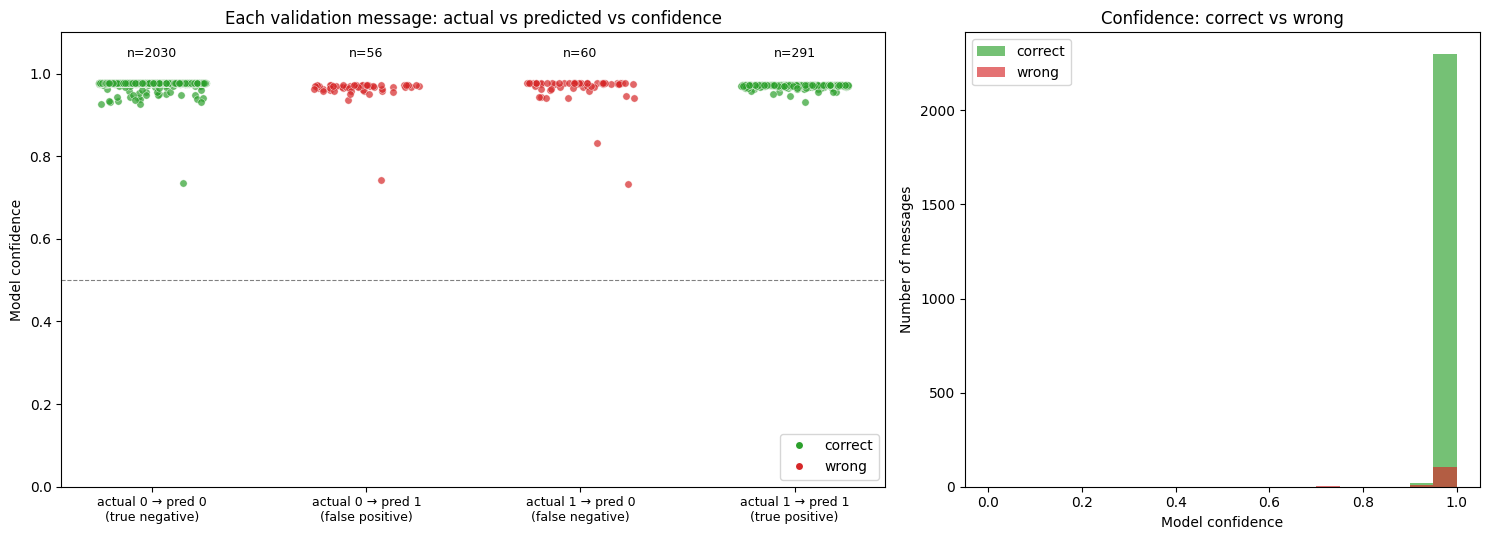

Mean confidence, correct predictions: 0.976
Mean confidence, wrong predictions:   0.964


In [17]:
plot_df = test_out.copy()
plot_df["confidence"] = pd.to_numeric(plot_df["confidence"], errors="coerce")
plot_df["actual"] = plot_df[LABEL_COL].astype(str)
plot_df["correct"] = plot_df["actual"] == plot_df["pred"].astype(str)

if plot_df["confidence"].isna().all():
    print("No confidence values were returned, so there is nothing to plot.")
else:
    # Group every message by (actual -> predicted) so all three things show up in one view
    groups = [("0", "0"), ("0", "1"), ("1", "0"), ("1", "1")]
    names = {
        ("0", "0"): "actual 0 → pred 0\n(true negative)",
        ("0", "1"): "actual 0 → pred 1\n(false positive)",
        ("1", "0"): "actual 1 → pred 0\n(false negative)",
        ("1", "1"): "actual 1 → pred 1\n(true positive)",
    }

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.6, 1]})

    # --- Left: one dot per message, confidence on the y-axis ---
    ax = axes[0]
    rng = np.random.default_rng(0)
    for i, (a, p) in enumerate(groups):
        sub = plot_df[(plot_df["actual"] == a) & (plot_df["pred"].astype(str) == p)]
        x = i + rng.uniform(-0.25, 0.25, len(sub))          # jitter so dots don't overlap
        ax.scatter(x, sub["confidence"], s=28, alpha=0.7,
                   color="tab:green" if a == p else "tab:red",
                   edgecolor="white", linewidth=0.4)
        ax.text(i, 1.04, f"n={len(sub)}", ha="center", fontsize=9)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([names[g] for g in groups], fontsize=9)
    ax.set_ylabel("Model confidence")
    ax.set_ylim(0, 1.1)
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=0.8)
    ax.set_title("Each validation message: actual vs predicted vs confidence")
    ax.legend(handles=[
        plt.Line2D([], [], marker="o", color="w", markerfacecolor="tab:green", label="correct"),
        plt.Line2D([], [], marker="o", color="w", markerfacecolor="tab:red", label="wrong"),
    ], loc="lower right")

    # --- Right: confidence distribution, correct vs wrong ---
    ax = axes[1]
    bins = np.linspace(0, 1, 21)
    ax.hist(plot_df.loc[plot_df["correct"], "confidence"].dropna(), bins=bins,
            alpha=0.65, color="tab:green", label="correct")
    ax.hist(plot_df.loc[~plot_df["correct"], "confidence"].dropna(), bins=bins,
            alpha=0.65, color="tab:red", label="wrong")
    ax.set_xlabel("Model confidence")
    ax.set_ylabel("Number of messages")
    ax.set_title("Confidence: correct vs wrong")
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Mean confidence, correct predictions:", round(plot_df.loc[plot_df["correct"], "confidence"].mean(), 3))
    print("Mean confidence, wrong predictions:  ", round(plot_df.loc[~plot_df["correct"], "confidence"].mean(), 3))

## Evaluation

In [18]:

y_true, y_pred = test_out[LABEL_COL], test_out["pred"]

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nClassification report:")
print(classification_report(y_true, y_pred, labels=["0", "1"],
                            target_names=["not offensive (0)", "offensive (1)"],
                            zero_division=0))
print("Confusion matrix (rows = actual, columns = predicted):")
print(pd.DataFrame(confusion_matrix(y_true, y_pred, labels=["0", "1"]),
                   index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"]))

Accuracy: 0.9524

Classification report:
                   precision    recall  f1-score   support

not offensive (0)       0.97      0.97      0.97      2086
    offensive (1)       0.84      0.83      0.83       351

         accuracy                           0.95      2437
        macro avg       0.90      0.90      0.90      2437
     weighted avg       0.95      0.95      0.95      2437

Confusion matrix (rows = actual, columns = predicted):
          pred 0  pred 1
actual 0    2030      56
actual 1      60     291


## Export Weights

In [14]:
import shutil
from google.colab import files

# 1. Create a zip archive of the folder
shutil.make_archive("my_folder", 'zip', OUTPUT_DIR)

# 2. Download the archive
files.download("my_folder.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>